# 📊 Telco Customer Churn - Exploratory Data Analysis (EDA)
**Objective**: Analyze customer behavior, demographics, service usage, and financial indicators to uncover the primary drivers of customer attrition.

> **Note**: These exploratory findings serve as the analytical foundation for the **Power BI Executive Dashboard** and guide feature selection for predictive modeling (`03_model.ipynb`).

---

### Key Questions Explored:
1. **Who is churning?** (Demographic & family profiles)
2. **What contract & tenure behaviors trigger churn?**
3. **The Fiber Optic paradox**: Why are premium internet customers churning?
4. **How do billing & payment methods impact attrition?**
5. **What is the financial impact (monthly revenue lost)?**


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Styling and visualization defaults
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
pd.set_option('display.max_columns', None)

# Palette definition
CHURN_PALETTE = {'No': '#3b82f6', 'Yes': '#ef4444'}
COLOR_PRIMARY = '#2563eb'
COLOR_CHURN = '#ef4444'
COLOR_SAFE = '#10b981'

print("Libraries imported and plotting theme initialized successfully!")


Libraries imported and plotting theme initialized successfully!


## 1. Data Ingestion & Sanity Check

In [2]:
data_path = os.path.join("..", "data", "telco_churn_cleaned.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("data", "telco_churn_cleaned.csv")

df = pd.read_csv(data_path)
print(f"Dataset Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Overall Churn Rate: {df['Churn_Numeric'].mean()*100:.2f}%")
df.head(3)


Dataset Loaded: 7,043 rows × 25 columns
Overall Churn Rate: 26.54%


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_Numeric,TotalAddonServices,TenureGroup,HasFamily
0,7590-VHVEG,Female,0,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,1,0-12m,1
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0,2,25-48m,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,2,0-12m,0


## 2. Demographic Analysis
Does customer churn depend on gender, senior citizen status, or family structure?


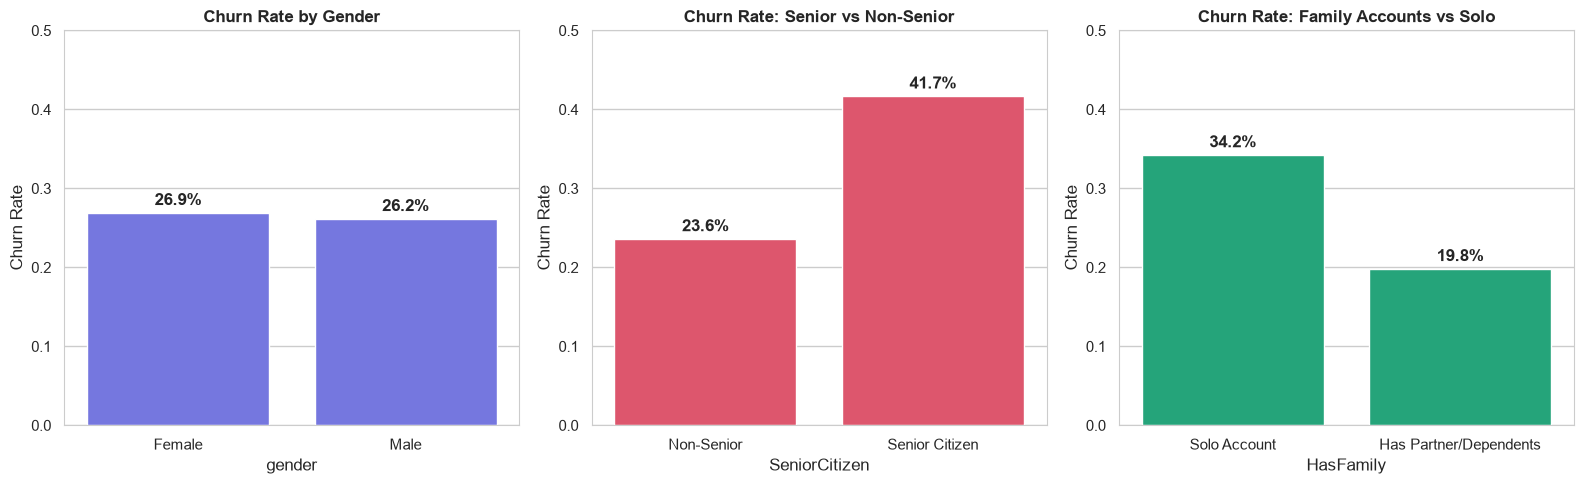

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Gender vs Churn
gender_churn = df.groupby('gender', observed=False)['Churn_Numeric'].mean().reset_index()
sns.barplot(data=gender_churn, x='gender', y='Churn_Numeric', color='#6366f1', ax=axes[0])
axes[0].set_title("Churn Rate by Gender", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Churn Rate")
axes[0].set_ylim(0, 0.5)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width()/2., p.get_height()),
                     ha='center', va='bottom', xytext=(0, 3), textcoords='offset points', fontweight='bold')

# 2. Senior Citizen vs Churn
senior_churn = df.groupby('SeniorCitizen', observed=False)['Churn_Numeric'].mean().reset_index()
senior_churn['SeniorCitizen'] = senior_churn['SeniorCitizen'].map({0: 'Non-Senior', 1: 'Senior Citizen'})
sns.barplot(data=senior_churn, x='SeniorCitizen', y='Churn_Numeric', color='#f43f5e', ax=axes[1])
axes[1].set_title("Churn Rate: Senior vs Non-Senior", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Churn Rate")
axes[1].set_ylim(0, 0.5)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width()/2., p.get_height()),
                     ha='center', va='bottom', xytext=(0, 3), textcoords='offset points', fontweight='bold')

# 3. Family Status vs Churn
family_churn = df.groupby('HasFamily', observed=False)['Churn_Numeric'].mean().reset_index()
family_churn['HasFamily'] = family_churn['HasFamily'].map({0: 'Solo Account', 1: 'Has Partner/Dependents'})
sns.barplot(data=family_churn, x='HasFamily', y='Churn_Numeric', color='#10b981', ax=axes[2])
axes[2].set_title("Churn Rate: Family Accounts vs Solo", fontsize=12, fontweight='bold')
axes[2].set_ylabel("Churn Rate")
axes[2].set_ylim(0, 0.5)
for p in axes[2].patches:
    axes[2].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width()/2., p.get_height()),
                     ha='center', va='bottom', xytext=(0, 3), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()


### 📌 Demographic Key Takeaways:
- **Gender is neutral**: Male (~26.2%) and Female (~26.9%) churn rates are practically identical. Gender should not be used as a primary retention targeting feature.
- **Senior Citizens are High-Risk**: Senior citizens churn at **41.7%**, compared to **23.6%** for younger demographics.
- **Family Accounts are Sticky**: Customers with a partner or dependents have a significantly lower churn rate (**19.7%**) compared to solo customers (**33.0%**).


## 3. Contract Type & Tenure Dynamics
The contract structure is the strongest single predictor of customer retention.


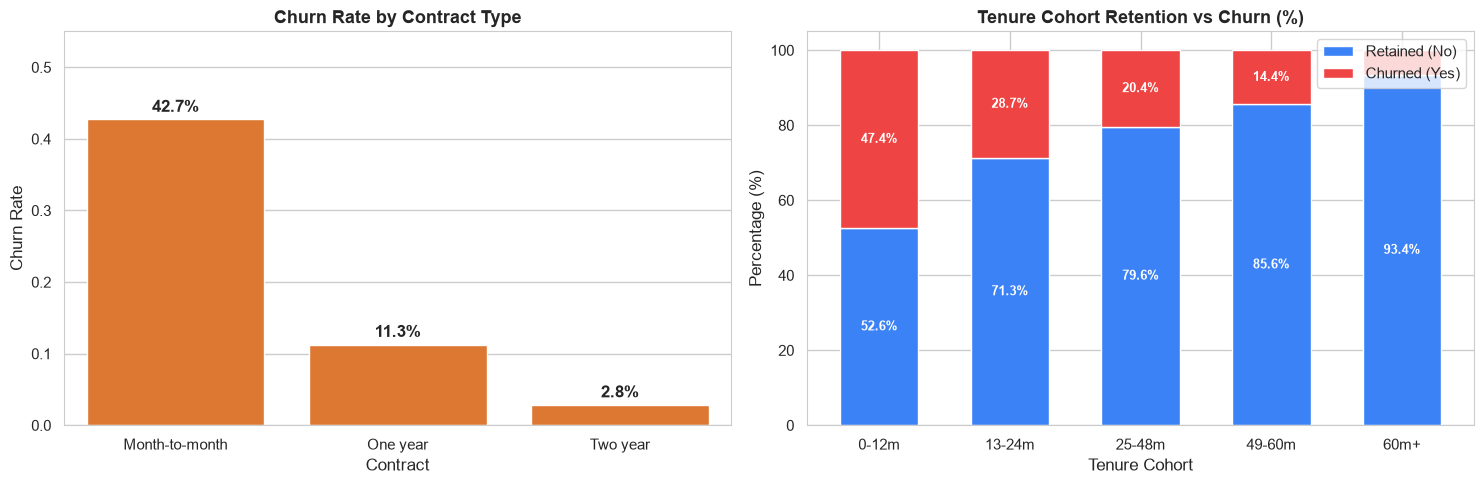

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# 1. Churn by Contract Type
contract_order = ['Month-to-month', 'One year', 'Two year']
contract_churn = df.groupby('Contract', observed=False)['Churn_Numeric'].agg(['mean', 'count']).reindex(contract_order).reset_index()
sns.barplot(data=contract_churn, x='Contract', y='mean', color='#f97316', ax=ax1)
ax1.set_title("Churn Rate by Contract Type", fontsize=13, fontweight='bold')
ax1.set_ylabel("Churn Rate")
ax1.set_ylim(0, 0.55)
for p in ax1.patches:
    ax1.annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width()/2., p.get_height()),
                 ha='center', va='bottom', xytext=(0, 3), textcoords='offset points', fontweight='bold')

# 2. Tenure Cohorts vs Churn Distribution
tenure_order = ['0-12m', '13-24m', '25-48m', '49-60m', '60m+']
tenure_data = df.groupby(['TenureGroup', 'Churn'], observed=False).size().unstack(fill_value=0).reindex(tenure_order)
tenure_pct = tenure_data.div(tenure_data.sum(axis=1), axis=0) * 100

tenure_pct[['No', 'Yes']].plot(kind='bar', stacked=True, color=['#3b82f6', '#ef4444'], ax=ax2, width=0.6)
ax2.set_title("Tenure Cohort Retention vs Churn (%)", fontsize=13, fontweight='bold')
ax2.set_ylabel("Percentage (%)")
ax2.set_xlabel("Tenure Cohort")
ax2.legend(["Retained (No)", "Churned (Yes)"], loc='upper right')
ax2.tick_params(axis='x', rotation=0)

for c in ax2.containers:
    for patch in c:
        h = patch.get_height()
        if h > 8:
            ax2.annotate(f"{h:.1f}%", (patch.get_x() + patch.get_width()/2., patch.get_y() + h/2.),
                         ha='center', va='center', color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()


### 📌 Contract & Tenure Key Takeaways:
- **Month-to-month Vulnerability**: Customers on month-to-month contracts have a **42.7% churn rate**, representing **88.6% of all churning customers**.
- **Long-term Contracts Retain**: One-year contract churn drops to **11.3%**, and Two-year contracts drop down to **2.8%**.
- **The 12-Month Cliff**: Nearly half (**47.4%**) of customers in their first year (`0-12m`) churn. Once a customer passes 24 months, retention increases sharply.


## 4. Internet Service & The Fiber Optic Paradox
Why do Fiber Optic customers have the highest churn rate despite being the fastest service?


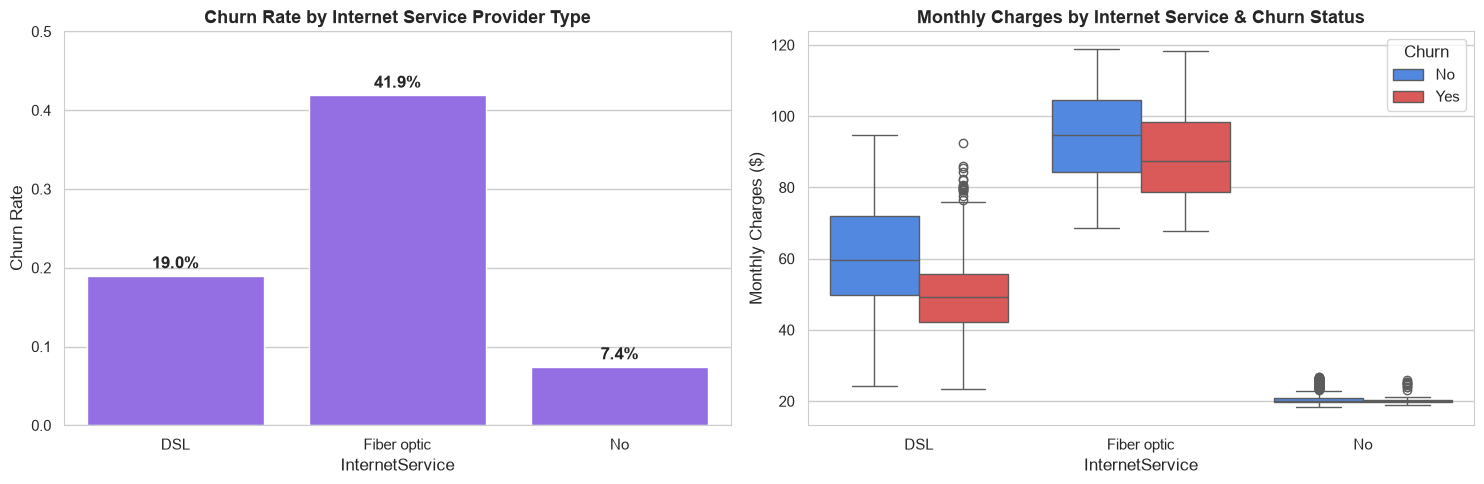

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# 1. Churn by Internet Service Type
internet_churn = df.groupby('InternetService', observed=False)['Churn_Numeric'].mean().reset_index()
sns.barplot(data=internet_churn, x='InternetService', y='Churn_Numeric', color='#8b5cf6', ax=ax1)
ax1.set_title("Churn Rate by Internet Service Provider Type", fontsize=13, fontweight='bold')
ax1.set_ylabel("Churn Rate")
ax1.set_ylim(0, 0.5)
for p in ax1.patches:
    ax1.annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width()/2., p.get_height()),
                 ha='center', va='bottom', xytext=(0, 3), textcoords='offset points', fontweight='bold')

# 2. Monthly Charges Distribution: DSL vs Fiber Optic vs No Internet
sns.boxplot(data=df, x='InternetService', y='MonthlyCharges', hue='Churn', palette=CHURN_PALETTE, ax=ax2)
ax2.set_title("Monthly Charges by Internet Service & Churn Status", fontsize=13, fontweight='bold')
ax2.set_ylabel("Monthly Charges ($)")

plt.tight_layout()
plt.show()


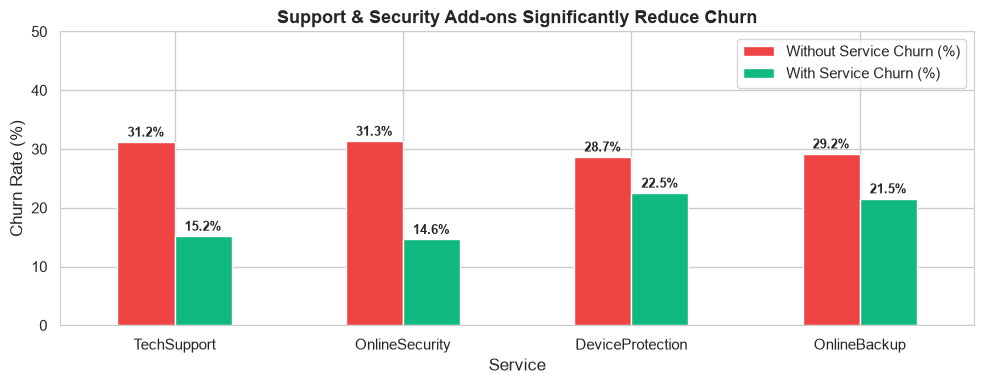

In [6]:
# Compare Churn for Customers With vs Without Tech Support and Online Security
addon_eval = []
for service in ['TechSupport', 'OnlineSecurity', 'DeviceProtection', 'OnlineBackup']:
    rate_yes = df[df[service] == 'Yes']['Churn_Numeric'].mean()
    rate_no = df[df[service] == 'No']['Churn_Numeric'].mean()
    addon_eval.append({'Service': service, 'With Service Churn (%)': rate_yes * 100, 'Without Service Churn (%)': rate_no * 100, 'Risk Reduction (%)': (rate_no - rate_yes) * 100})

addon_df = pd.DataFrame(addon_eval)
fig, ax = plt.subplots(figsize=(10, 4))
addon_df.set_index('Service')[['Without Service Churn (%)', 'With Service Churn (%)']].plot(kind='bar', color=['#ef4444', '#10b981'], ax=ax)
ax.set_title("Support & Security Add-ons Significantly Reduce Churn", fontsize=13, fontweight='bold')
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, 50)
ax.tick_params(axis='x', rotation=0)
for c in ax.containers:
    for patch in c:
        h = patch.get_height()
        ax.annotate(f"{h:.1f}%", (patch.get_x() + patch.get_width()/2., h),
                     ha='center', va='bottom', xytext=(0, 2), textcoords='offset points', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()


### 📌 Services & Support Key Takeaways:
- **Fiber Optic Churn Rate is 41.9%** (vs 19.0% for DSL and 7.4% for No Internet).
- **The Cause**: Fiber optic costs an average of **~$91/month** (vs ~$58/month for DSL). When premium-paying customers encounter technical issues without Tech Support, they churn quickly.
- **Tech Support & Online Security cut churn in half**: Customers with TechSupport churn at only **15.2%** vs **31.2%** without it.


## 5. Billing Methods & Financial Revenue Impact
How do payment methods influence churn, and what is the exact monthly revenue loss?


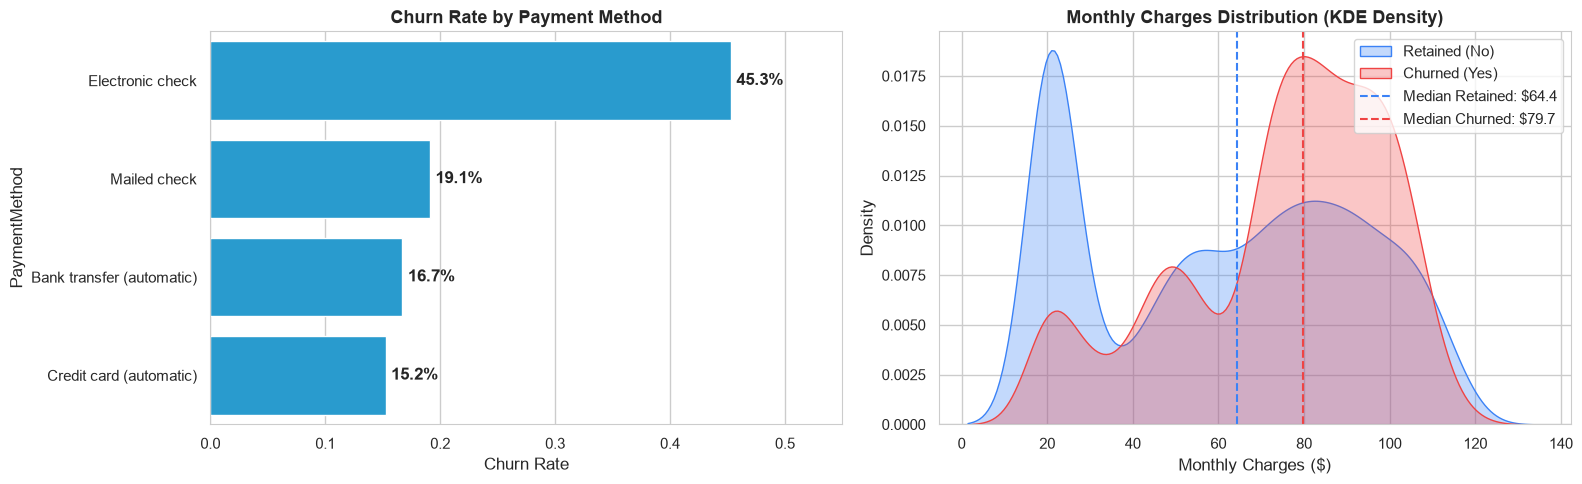

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# 1. Churn Rate by Payment Method
payment_order = ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
payment_churn = df.groupby('PaymentMethod', observed=False)['Churn_Numeric'].mean().reindex(payment_order).reset_index()

sns.barplot(data=payment_churn, x='Churn_Numeric', y='PaymentMethod', color='#0ea5e9', ax=ax1)
ax1.set_title("Churn Rate by Payment Method", fontsize=13, fontweight='bold')
ax1.set_xlabel("Churn Rate")
ax1.set_xlim(0, 0.55)
for p in ax1.patches:
    ax1.annotate(f"{p.get_width()*100:.1f}%", (p.get_width(), p.get_y() + p.get_height()/2.),
                 ha='left', va='center', xytext=(4, 0), textcoords='offset points', fontweight='bold')

# 2. KDE Plot of Monthly Charges for Churn vs Non-Churn
sns.kdeplot(data=df[df['Churn']=='No']['MonthlyCharges'], label='Retained (No)', color='#3b82f6', fill=True, alpha=0.3, ax=ax2)
sns.kdeplot(data=df[df['Churn']=='Yes']['MonthlyCharges'], label='Churned (Yes)', color='#ef4444', fill=True, alpha=0.3, ax=ax2)
ax2.axvline(df[df['Churn']=='No']['MonthlyCharges'].median(), color='#3b82f6', linestyle='--', label=f"Median Retained: ${df[df['Churn']=='No']['MonthlyCharges'].median():.1f}")
ax2.axvline(df[df['Churn']=='Yes']['MonthlyCharges'].median(), color='#ef4444', linestyle='--', label=f"Median Churned: ${df[df['Churn']=='Yes']['MonthlyCharges'].median():.1f}")
ax2.set_title("Monthly Charges Distribution (KDE Density)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Monthly Charges ($)")
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()


In [8]:
# Financial quantification of churn
total_monthly_rev = df['MonthlyCharges'].sum()
churned_monthly_rev = df[df['Churn'] == 'Yes']['MonthlyCharges'].sum()
churn_rev_pct = (churned_monthly_rev / total_monthly_rev) * 100

elec_check_rev_loss = df[(df['Churn'] == 'Yes') & (df['PaymentMethod'] == 'Electronic check')]['MonthlyCharges'].sum()

print("="*60)
print("💰 TELCO REVENUE LOSS ANALYSIS:")
print(f"  • Total Monthly Recurring Revenue (MRR):     ${total_monthly_rev:,.2f}")
print(f"  • Monthly Revenue Lost to Churn:              ${churned_monthly_rev:,.2f} ({churn_rev_pct:.1f}% of total MRR)")
print(f"  • Annualized Revenue Lost (Run-Rate):         ${churned_monthly_rev * 12:,.2f}/year")
print(f"  • Revenue Lost from 'Electronic Check' alone: ${elec_check_rev_loss:,.2f} ({elec_check_rev_loss/churned_monthly_rev*100:.1f}% of all lost revenue)")
print("="*60)


💰 TELCO REVENUE LOSS ANALYSIS:
  • Total Monthly Recurring Revenue (MRR):     $456,116.60
  • Monthly Revenue Lost to Churn:              $139,130.85 (30.5% of total MRR)
  • Annualized Revenue Lost (Run-Rate):         $1,669,570.20/year
  • Revenue Lost from 'Electronic Check' alone: $84,288.75 (60.6% of all lost revenue)


### 📌 Billing & Financial Key Takeaways:
- **Electronic Check is the most volatile payment method**: Has a **45.3% churn rate**, compared to ~15-18% for automatic payment channels (Credit card / Bank transfer).
- **Higher Monthly Charges correlate with higher churn**: Median monthly charge for churned customers is **$79.65**, vs **$64.45** for retained customers.
- **Over $1.67 Million Annualized Revenue Loss**: Churn accounts for **$139,130/month** in direct lost revenue, with over 57% originating from Electronic Check users.


## 6. Correlation Analysis with Churn
Which variables show the strongest linear and rank correlation with the target variable `Churn_Numeric`?


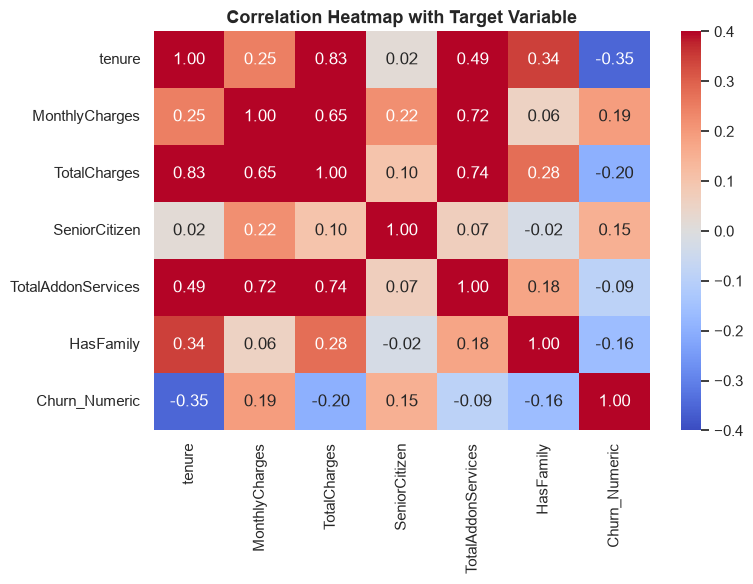

In [9]:
# Select numerical and key binary encoded features for correlation
corr_cols = [
    'tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 
    'TotalAddonServices', 'HasFamily', 'Churn_Numeric'
]
corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.4, vmax=0.4, center=0, cbar=True, ax=ax)
ax.set_title("Correlation Heatmap with Target Variable", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 7. Executive Summary & Actionable Recommendations

| Customer Segment | Churn Rate | Business Risk | Recommended Retention Action (Power BI KPI) |
|---|---|---|---|
| **Month-to-month Contract** | **42.7%** | Critical (88% of all churn) | Offer targeted 1-year contract discount at month 3 and month 9. |
| **Fiber Optic + No Tech Support** | **41.9%** | High Revenue Loss | Bundle free 3-month TechSupport with all Fiber Optic plans. |
| **Electronic Check Payment** | **45.3%** | Very High | Offer a one-time $10 credit to switch to Automated Bank Transfer. |
| **New Customers (< 12 Months)** | **47.4%** | Critical Drop-off | Implement proactive 30-day and 90-day onboarding satisfaction calls. |
| **Senior Citizens** | **41.7%** | High | Provide dedicated senior support hotline and simplified billing. |

---
*Ready for Phase 3: Machine Learning Model Development (`03_model.ipynb`)*
